# STEP 4 — 미추홀구 I-MOD 후보 정류장군 우선 검토 분석

**목표:** 286개 정류장군 전체를 보존하면서, 수요 적격성 → 다기준 우선순위 → 민감도 → 시간대별 패턴을 확인한다.

**주의:** 시간적 불일치·낮은 운행횟수·운행당 승객수는 **실제 미충족 수요, 버스 혼잡도, 대기시간, I-MOD 편익**을 직접 측정하지 않는다. 우선순위는 *추가 현장검증 대상 선정*을 위한 탐색적 지표다.

- 6월 11일은 의도적으로 제외한 90일 자료
- 공간 위치가 불확실한 정류장군도 통계 평가에서는 포함
- 정류장군 유형(K-Means/GMM)은 참고 정보이며 점수에 가산하지 않음
- 입력 파일 3개: `03_features_expanded_286.csv`, `02_station_assignments_286.csv`, `04_StopGroup_Hourly_2026Q2.csv`
- `런타임 → 모두 실행` 후 업로드 창에서 3개 CSV 선택

In [4]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
from IPython.display import display
from google.colab import files
import io, zipfile, warnings
warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='whitegrid')
OUT=Path('IMOD_STEP4_Results'); OUT.mkdir(exist_ok=True)
uploaded=files.upload()

def load_marker(marker):
    matches=[name for name in uploaded if marker in name]
    if len(matches)!=1:
        raise ValueError(f'파일 구분 실패: {marker}. 발견: {matches}. 필요한 CSV 3개를 정확히 선택하세요.')
    return pd.read_csv(io.BytesIO(uploaded[matches[0]]), encoding='utf-8-sig')

features=load_marker('features_expanded_286')
clusters=load_marker('station_assignments_286')
hourly=load_marker('StopGroup_Hourly')
print('Features',features.shape,'Clusters',clusters.shape,'Hourly',hourly.shape)

Saving 02_station_assignments_286.csv to 02_station_assignments_286.csv
Saving 03_features_expanded_286.csv to 03_features_expanded_286 (2).csv
Saving 04_StopGroup_Hourly_2026Q2.csv to 04_StopGroup_Hourly_2026Q2 (2).csv
Features (286, 34) Clusters (286, 12) Hourly (617760, 25)


## 1. 데이터 일관성 및 품질검사

결측·중복·음수와 군집 할당을 검증한다. **정류장명이 행을 유일하게 식별하는지** 확인하고 원래 286개 대상이 유지됐는지 검사한다.

In [5]:
assert len(features)==286 and features.station_name.nunique()==286, 'Features 정류장명 고유 개수 확인 필요'
assert clusters.station_name.nunique()==286, '군집 할당 개수 확인 필요'
assert hourly.station_name.nunique()==286, 'Hourly 정류장명 개수 확인 필요'
assert len(hourly)==617760, '시간대 자료 행 수를 확인하세요'
assert not hourly.duplicated(['date','station_name','hour']).any(), '시간대 키 중복'
assert (hourly[['passenger_count','operation_count']]>=0).all().all(), '음수 기록 존재'
df=features.merge(clusters[['station_name','KMeans_FULL8','GMM_ROUTE6']],on='station_name',how='left',validate='one_to_one')
assert df['KMeans_FULL8'].notna().all(), 'KMeans 할당 누락'
print('분석 대상',len(df),'| 노선 수 결측',df.unique_route_count.isna().sum())
print('수요 중앙값',round(df.avg_daily_passengers.median(),3))
print('공급 0·수요 양수 시간대',int((hourly.passenger_positive_operation_zero==1).sum()))
display(df[['station_name','avg_daily_passengers','temporal_mismatch','KMeans_FULL8']].head())

분석 대상 286 | 노선 수 결측 2
수요 중앙값 266.811
공급 0·수요 양수 시간대 3143


,station_name,avg_daily_passengers,temporal_mismatch,KMeans_FULL8
0,(주)세모입구(린나이코리아),58.577778,0.356517,1
1,6공단사거리,8.377778,0.255365,0
2,6공단입구,47.066667,0.226813,0
3,JC회관,140.066667,0.227516,1
4,KT인천지사,492.911111,0.182810,0


## 2. 후보 적격성: 286개는 유지하되 수요 기준을 따로 표시

기본 적격성은 **일평균 승차량 전체 중앙값 이상**으로 정한다. 최종 결론이 아니라 민감도를 검증할 *가정*이며, 하위 정류장들을 원본에서 삭제하지 않는다.

In [6]:
p25=float(df.avg_daily_passengers.quantile(.25)); med=float(df.avg_daily_passengers.median())
df['eligible_median']=df.avg_daily_passengers>=med
df['eligible_p25']=df.avg_daily_passengers>=p25
summary=pd.DataFrame({'scenario':['all_286','demand_ge_p25','demand_ge_median'], 'cutoff':[0,p25,med], 'eligible_count':[286,int(df.eligible_p25.sum()),int(df.eligible_median.sum())]})
display(summary);summary.to_csv(OUT/'01_eligibility_summary.csv',index=False,encoding='utf-8-sig')

,scenario,cutoff,eligible_count
0,all_286,0.000000,286
1,demand_ge_p25,77.300000,214
2,demand_ge_median,266.811111,143


## 3. 지표 변환과 우선 검토 점수

원래 데이터의 **경험적 백분위(0~100)** 를 사용해 서로 다른 단위를 맞춘다. 승차량, 시간적 불일치, 저공급 시간 비율, 운행당 승객수가 높을수록 우선 검토 점수 상승.

기본 가중치 = 수요 25% + 시간 불일치 35% + 저공급 20% + 운행당 승객 20%. 이는 정책 결정값이 아니라 비교용 시나리오다.

고유 노선 수는 공급량과 매우 높은 상관이 있으므로 기본 점수에서 제외하고 보조 시나리오에서만 비교한다.

In [7]:
indicators={'demand':'avg_daily_passengers','mismatch':'temporal_mismatch','low_supply':'low_supply_hour_ratio_lt1avg','intensity':'passengers_per_operation'}
for name,col in indicators.items():
    df[f'percentile_{name}']=df[col].rank(pct=True,method='average')*100
# 노선 수는 2개 결측: 보조 정보로만 사용
weights={
 'base':{'demand':.25,'mismatch':.35,'low_supply':.20,'intensity':.20},
 'demand_priority':{'demand':.45,'mismatch':.25,'low_supply':.15,'intensity':.15},
 'time_priority':{'demand':.15,'mismatch':.50,'low_supply':.25,'intensity':.10},
 'balanced':{'demand':.25,'mismatch':.25,'low_supply':.25,'intensity':.25},
}
assert all(np.isclose(sum(w.values()),1) for w in weights.values())
for s,w in weights.items():
    df[f'score_{s}']=sum(df[f'percentile_{k}']*v for k,v in w.items())
    df[f'rank_{s}']=df[f'score_{s}'].rank(ascending=False,method='min').astype(int)
# 전체 순위를 먼저 계산하고, 적격성 필터에 따라 별도 후보 테이블 생성
base=df.loc[df.eligible_median].sort_values('score_base',ascending=False).copy()
base['eligible_rank']=np.arange(1,len(base)+1)
columns=['station_name','stop_group_id','KMeans_FULL8','GMM_ROUTE6','avg_daily_passengers','avg_daily_operations','passengers_per_operation','temporal_mismatch','low_supply_hour_ratio_lt1avg','unique_route_count','spatial_group_status','score_base','eligible_rank']
display(base[columns].head(20).round(3))
df.to_csv(OUT/'02_all_286_with_scores.csv',index=False,encoding='utf-8-sig')
base[columns].to_csv(OUT/'03_base_eligible_ranking.csv',index=False,encoding='utf-8-sig')

,station_name,stop_group_id,KMeans_FULL8,GMM_ROUTE6,avg_daily_passengers,avg_daily_operations,passengers_per_operation,temporal_mismatch,low_supply_hour_ratio_lt1avg,unique_route_count,spatial_group_status,score_base,eligible_rank
38,남중학교,SG039,0,1,576.089,310.744,1.854,0.232,0.208,5.0,nearby_stop_group,73.776,1
205,인하대후문,SG206,2,2,2666.889,679.611,3.924,0.247,0.167,5.0,spatially_split_ambiguous,73.776,2
67,롯데백화점(인천터미널),SG068,2,2,10306.456,2553.289,4.037,0.231,0.167,26.0,single_stop,72.133,3
69,문학경기장(야구장),SG070,1,0,309.478,456.133,0.678,0.411,0.208,7.0,single_stop,69.318,4
242,주안역,SG243,2,2,4220.600,1591.611,2.652,0.213,0.167,17.0,nearby_stop_group,68.846,5
75,문학초등학교,SG076,0,1,925.789,554.244,1.670,0.187,0.208,4.0,nearby_stop_group,67.290,6
166,용현3동행정복지센터.보훈병원,SG167,0,1,1206.344,716.678,1.683,0.180,0.208,5.0,nearby_stop_group,67.220,7
278,한양아파트,SG279,0,1,274.956,213.411,1.288,0.241,0.208,2.0,nearby_stop_group,66.486,8
232,주안7동행정복지센터,SG233,0,1,1608.400,912.022,1.764,0.171,0.208,6.0,nearby_stop_group,65.559,9
135,신기.남부종합시장(진흥사거리),SG136,2,1,2182.700,997.444,2.188,0.197,0.167,8.0,nearby_stop_group,65.122,10


## 4. 기본 후보 TOP 20과 군집 분포

군집 유형은 점수에 포함하지 않고 **어느 군집에 후보가 집중되는지 사후 점검**한다. TOP 20은 전체 286개가 아니라 **중앙값 이상 적격 정류장군 내 상위 20개**이다.

/tmp/ipykernel_1184/937183544.py:3: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  plt.title('Candidate review priority — demand ≥ median (top 20)');plt.xlabel('Relative screening score (0–100)');plt.ylabel('Station group');plt.tight_layout()
/tmp/ipykernel_1184/937183544.py:3: UserWarning: Glyph 52380 (\N{HANGUL SYLLABLE CEON}) missing from font(s) DejaVu Sans.
  plt.title('Candidate review priority — demand ≥ median (top 20)');plt.xlabel('Relative screening score (0–100)');plt.ylabel('Station group');plt.tight_layout()
/tmp/ipykernel_1184/937183544.py:3: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  plt.title('Candidate review priority — demand ≥ median (top 20)');plt.xlabel('Relative screening score (0–100)');plt.ylabel('Station group');plt.tight_layout()
/tmp/ipykernel_1184/937183544.py:3: UserWarning: Glyph 44228 (\N{HANGUL SYLLABLE GYE}) missing from font(s) DejaVu Sans.
  plt.title('Candidate review p

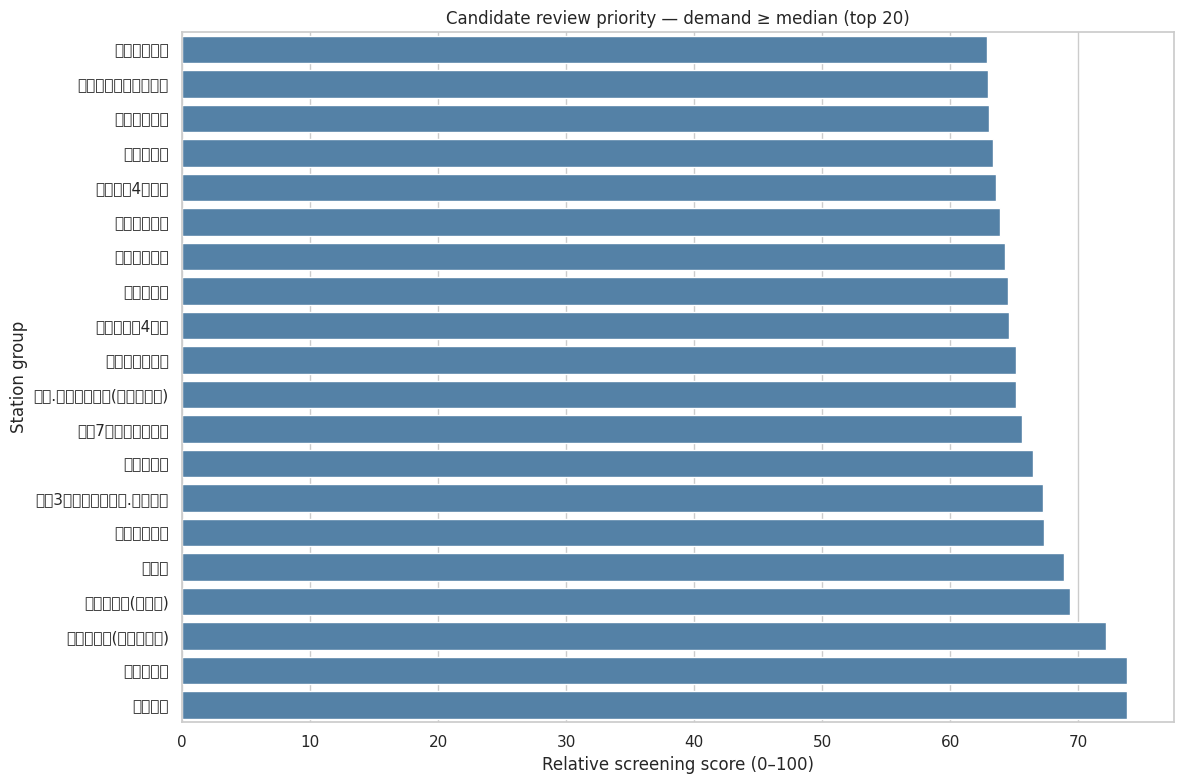

군집별 수요 적격성


eligible_median,False,True
KMeans_FULL8,,
0,81,115
1,62,3
2,0,25


기본 상위 20의 군집 구성


,count
KMeans_FULL8,
0,14
1,2
2,4


In [8]:
top=base.head(20).iloc[::-1]
plt.figure(figsize=(12,8));sns.barplot(data=top,x='score_base',y='station_name',color='steelblue')
plt.title('Candidate review priority — demand ≥ median (top 20)');plt.xlabel('Relative screening score (0–100)');plt.ylabel('Station group');plt.tight_layout()
plt.savefig(OUT/'04_top20_screening_scores.png',dpi=170,bbox_inches='tight');plt.show()
ct=pd.crosstab(df.KMeans_FULL8,df.eligible_median)
print('군집별 수요 적격성');display(ct)
print('기본 상위 20의 군집 구성');display(base.head(20).KMeans_FULL8.value_counts().sort_index())
ct.to_csv(OUT/'05_cluster_eligibility_counts.csv',encoding='utf-8-sig')

## 5. 가중치·수요 기준 민감도

각 조건에서 **상위 20개 후보의 교집합(Jaccard)과 순위 변동**을 계산한다. 수요 컷오프를 바꾸면 후보 집합 자체가 달라지므로, 단순 실루엣 점수처럼 해석하면 안 된다.

,scenario,top20_overlap_count,top20_jaccard
5,median__base,20,1.000000
9,p25__base,13,0.481481
4,median__balanced,13,0.481481
7,median__time_priority,13,0.481481
8,p25__balanced,11,0.379310
0,all__balanced,11,0.379310
1,all__base,11,0.379310
2,all__demand_priority,10,0.333333
10,p25__demand_priority,10,0.333333
6,median__demand_priority,10,0.333333


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 47928 (\N{HANGUL SYLLABLE MUN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr

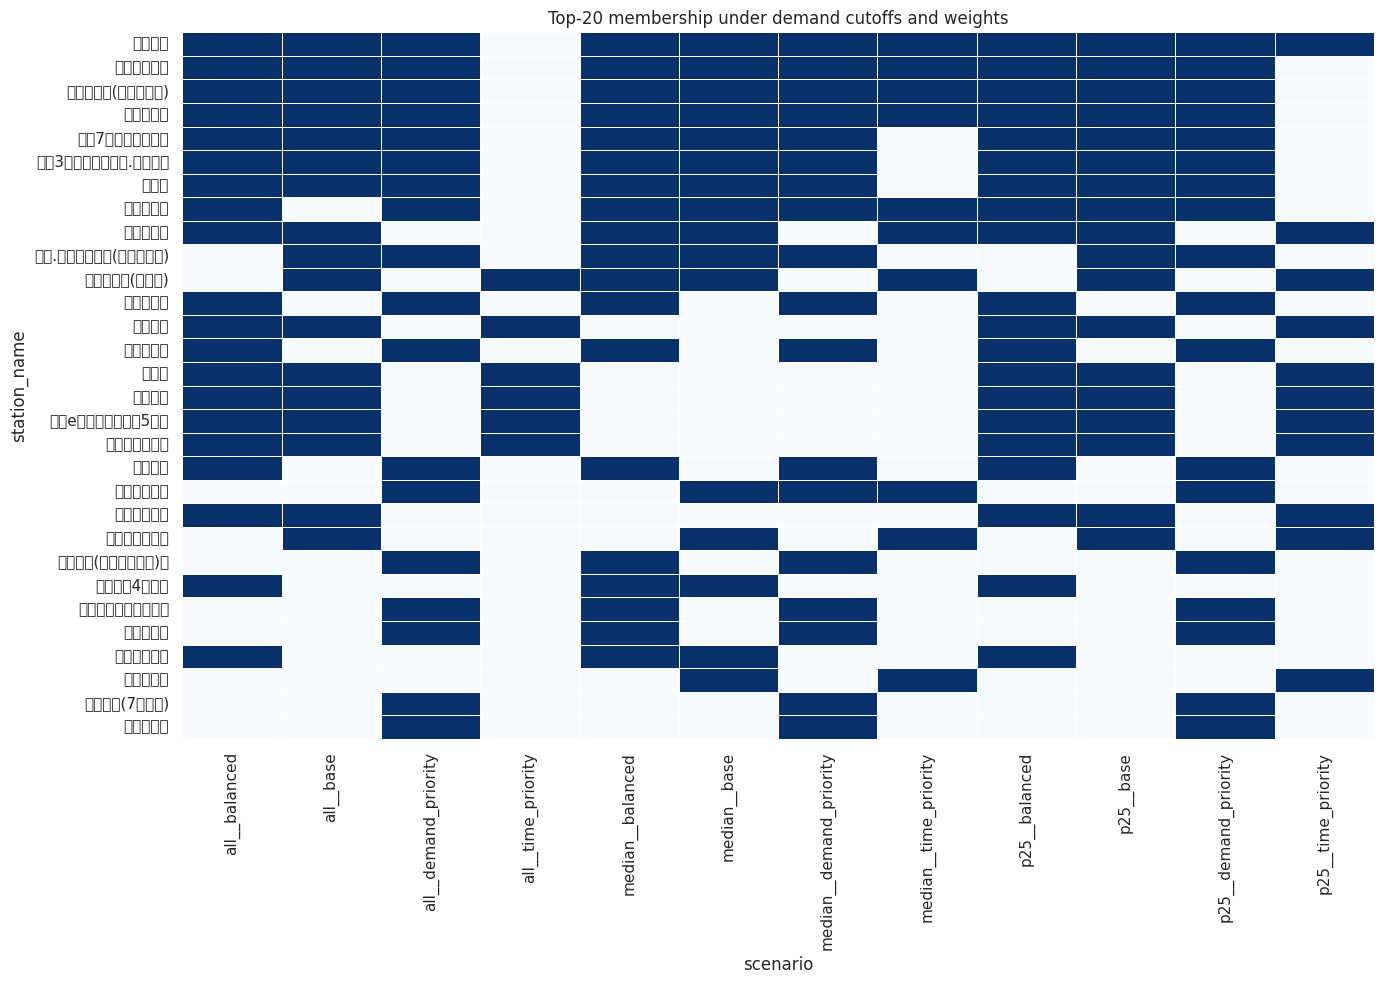

In [9]:
scenarios=[]
for cutoff_name,cutoff in [('all',0),('p25',p25),('median',med)]:
 for wname in weights:
    subset=df[df.avg_daily_passengers>=cutoff].sort_values(f'score_{wname}',ascending=False).copy()
    subset['scenario_rank']=np.arange(1,len(subset)+1)
    subset['scenario']=cutoff_name+'__'+wname
    scenarios.append(subset[['scenario','station_name','scenario_rank',f'score_{wname}']].rename(columns={f'score_{wname}':'scenario_score'}))
scenario=pd.concat(scenarios,ignore_index=True)
scenario.to_csv(OUT/'06_scenario_rankings.csv',index=False,encoding='utf-8-sig')
reference=set(scenario[(scenario.scenario=='median__base') & (scenario.scenario_rank<=20)].station_name)
rows=[]
for name,g in scenario.groupby('scenario'):
 s=set(g.nsmallest(20,'scenario_rank').station_name)
 rows.append({'scenario':name,'top20_overlap_count':len(reference&s),'top20_jaccard':len(reference&s)/len(reference|s)})
stability=pd.DataFrame(rows).sort_values('top20_overlap_count',ascending=False)
display(stability)
stability.to_csv(OUT/'07_top20_sensitivity.csv',index=False,encoding='utf-8-sig')
mat=scenario[scenario.scenario_rank<=20].assign(in_top20=1).pivot_table(index='station_name',columns='scenario',values='in_top20',fill_value=0)
mat=mat.loc[mat.sum(axis=1).sort_values(ascending=False).head(30).index]
plt.figure(figsize=(14,10));sns.heatmap(mat,cmap='Blues',cbar=False,linewidths=.4)
plt.title('Top-20 membership under demand cutoffs and weights');plt.tight_layout()
plt.savefig(OUT/'08_top20_scenario_heatmap.png',dpi=170,bbox_inches='tight');plt.show()

## 6. 시간대별 수요·공급 상대 패턴

상위 10개 후보의 전체 관측기간 시간대별 합계를 사용한다. **시간대별 수요 비중 vs 운행 비중**을 비교하는 것으로, 절대 수송 용량이나 대기시간을 계산하지 않는다.

두 분포의 차이 `demand_share - operation_share`는 상대적 배치 불일치이며 **0 운행 시간대에 수요가 있었다고 해서 실제 버스가 미운행했다고 단정할 수 없다.**

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:15: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  fig.savefi

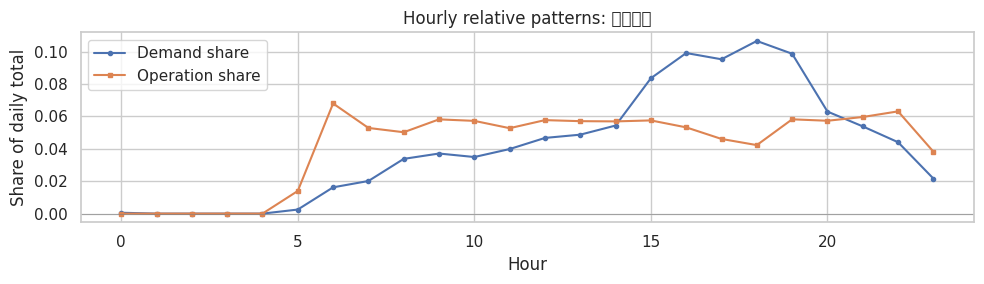

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 45824 (\N{HANGUL SYLLABLE DAE}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 54980 (\N{HANGUL SYLLABLE HU}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 47928 (\N{HANGUL SYLLABLE MUN}) missing from font(s) DejaVu Sans.
  ax.set_xlabel(

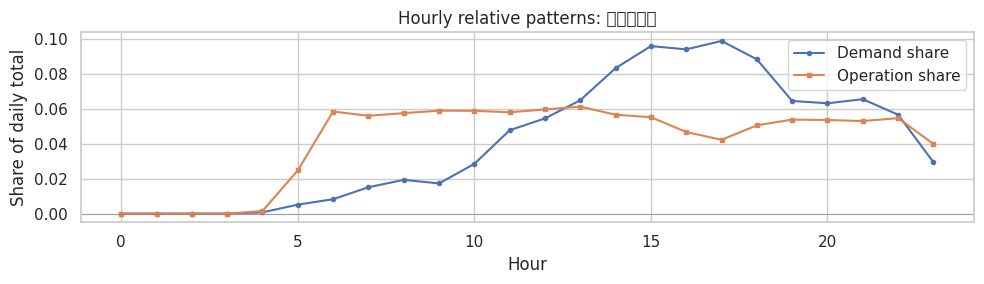

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 47215 (\N{HANGUL SYLLABLE ROS}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 45936 (\N{HANGUL SYLLABLE DE}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 48177 (\N{HANGUL SYLLABLE BAEG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 54868 (\N{HANGUL SYLLABLE HWA}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 51216 (\N{HANGUL SYLLABLE JEOM}) missing from font(s) DejaVu Sans.
  ax.set_xla

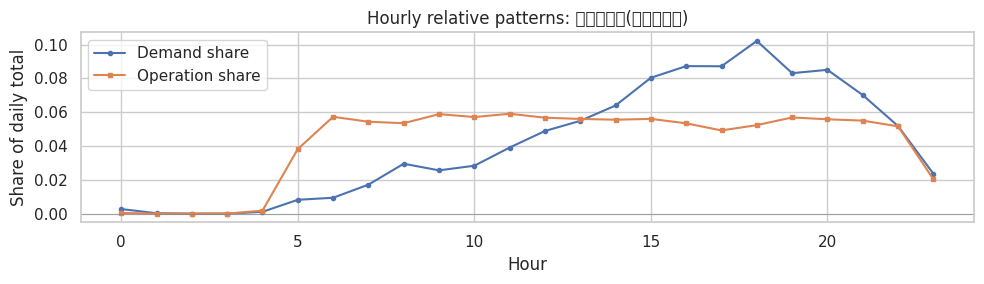

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 44221 (\N{HANGUL SYLLABLE GYEONG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 44592 (\N{HANGUL SYLLABLE GI}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 51109 (\N{HANGUL SYLLABLE JANG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 50556 (\N{HANGUL SYLLABLE YA}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 44396 (\N{HANGUL SYLLABLE GU}) missing from font(s) DejaVu Sans.
  ax.set_xla

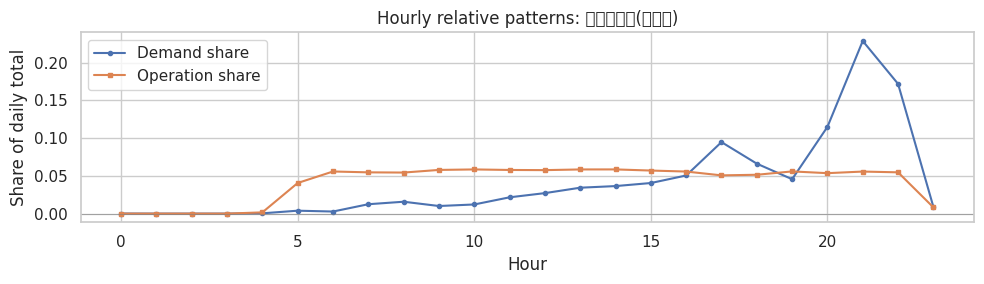

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 50504 (\N{HANGUL SYLLABLE AN}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 50669 (\N{HANGUL SYLLABLE YEOG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:15: UserWarning: Glyph 51452 (\N{HANGUL SYLLABLE JU}) missing from font(s) DejaVu Sans.
  fig.savefig(OUT/f'10_hourly_profile_{top_names.index(station)+1:02d}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
/tmp/ipykernel_1184/2569890500.py:15: UserWarning: Glyph 50504 (\N{HANGUL SYLLABLE AN}) missing from

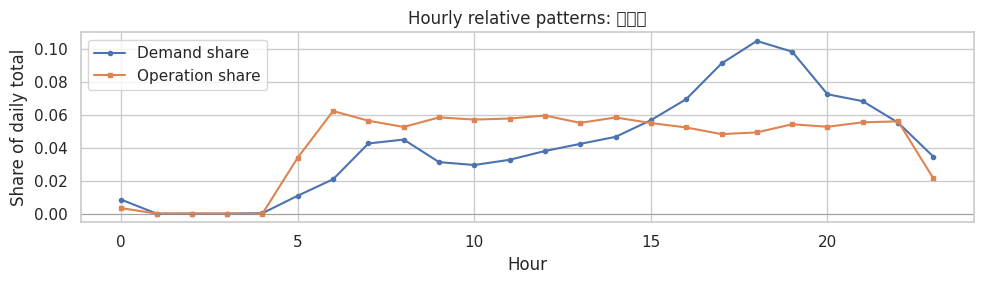

/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:14: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
/tmp/ipykernel_1184/2569890500.py:15: UserWarning: Glyph 52488 (\N{HANGUL SYLLABLE CO}) missing from font(s) DejaVu Sans.
  fig.savefig(OUT/f'10_hourly_profile_{top_names.index(station)+1:02d}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
/tmp/ipykernel_1184/2569890500.py:15: UserWarning: Glyph 46321 (\N{HANGUL SYLLABLE DEUNG}) missing from font(s) DejaVu Sans.
  fig.savefig(OUT/f'10_hourly_profile_{top_names.index(station)+1:02d}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylab

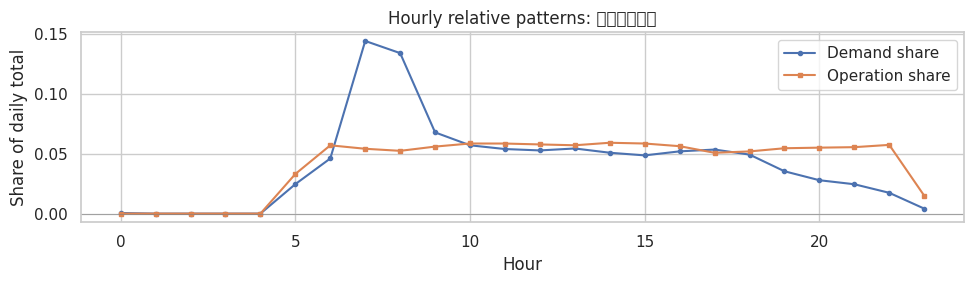

,station_name,hour,relative_gap
69,문학경기장(야구장),21,0.173158
223,한양아파트,7,0.140492
79,문학초등학교,7,0.090125
18,남중학교,18,0.064240
161,인하대후문,17,0.056516
210,주안역,18,0.055534
42,롯데백화점(인천터미널),18,0.049807
111,신기.남부종합시장(진흥사거리),15,0.036534
183,주안7동행정복지센터,15,0.029207
137,용현3동행정복지센터.보훈병원,17,0.025630


In [10]:
top_names=base.head(10).station_name.tolist()
h=hourly[hourly.station_name.isin(top_names)].copy()
profiles=h.groupby(['station_name','hour'],as_index=False)[['passenger_count','operation_count']].sum()
profiles['demand_share']=profiles.passenger_count / profiles.groupby('station_name').passenger_count.transform('sum').replace(0,np.nan)
profiles['operation_share']=profiles.operation_count / profiles.groupby('station_name').operation_count.transform('sum').replace(0,np.nan)
profiles['relative_gap']=profiles.demand_share-profiles.operation_share
profiles.to_csv(OUT/'09_top10_hourly_profiles.csv',index=False,encoding='utf-8-sig')
for station in top_names[:6]:
 d=profiles[profiles.station_name==station].sort_values('hour')
 fig,ax=plt.subplots(figsize=(10,3))
 ax.plot(d.hour,d.demand_share,label='Demand share',marker='o',markersize=3)
 ax.plot(d.hour,d.operation_share,label='Operation share',marker='s',markersize=3)
 ax.axhline(0,color='gray',linewidth=.4);ax.set_title(f'Hourly relative patterns: {station}')
 ax.set_xlabel('Hour');ax.set_ylabel('Share of daily total');ax.legend();fig.tight_layout()
 fig.savefig(OUT/f'10_hourly_profile_{top_names.index(station)+1:02d}.png',dpi=150,bbox_inches='tight');plt.show();plt.close(fig)
# 상대 수요 비중이 공급 비중을 가장 크게 초과하는 시간 표시 (추가 검증용)
peak_gap=profiles.loc[profiles.groupby('station_name').relative_gap.idxmax(),['station_name','hour','relative_gap']].sort_values('relative_gap',ascending=False)
display(peak_gap)
peak_gap.to_csv(OUT/'11_largest_relative_gap_hours.csv',index=False,encoding='utf-8-sig')

## 7. 후보군 월별 검증

월별 수요 규모 변화가 큰 후보는 따로 표시한다. 이 검증은 **군집의 월별 재학습 안정성**이 아니라 선택된 후보의 수요 변화 검증이다.

,0
station_name,
인하대후문,0.113057
문학경기장(야구장),0.091502
용현고가교,0.075120
인천고등학교,0.064064
인하대역4번출구,0.056137
관교여자중학교,0.054988
한양아파트,0.050686
인천비즈니스고등학교,0.045984
숭의보건지소,0.035902


/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 45224 (\N{HANGUL SYLLABLE NAM}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51473 (\N{HANGUL SYLLABLE JUNG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 54617 (\N{HANGUL SYLLABLE HAG}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 44368 (\N{HANGUL SYLLABLE GYO}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 51064 (\N{HANGUL SYLLABLE IN}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/local/lib/python3.13/dist-packages/seaborn/utils.py:61: UserWarning: Glyph 54616 (\N{HANGUL SYLLABLE HA}) missing from font(s) DejaVu Sans.
  fig.canvas.draw()
/usr/

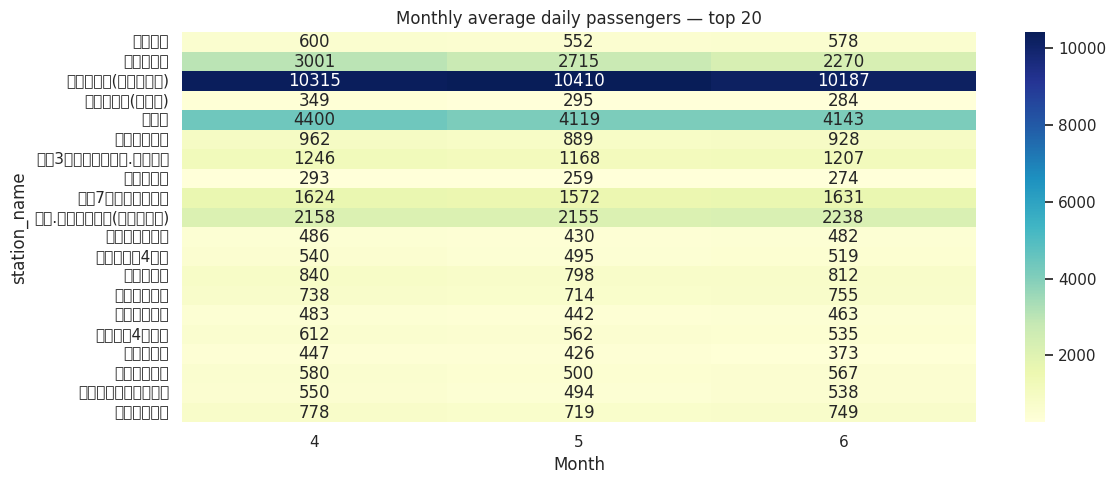

In [11]:
hourly['date']=pd.to_datetime(hourly['date'].astype(str),format='%Y%m%d',errors='raise')
hourly['month']=hourly['date'].dt.month
monthly=hourly[hourly.station_name.isin(base.head(20).station_name)].groupby(['station_name','month'],as_index=False).agg(total_passengers=('passenger_count','sum'),total_operations=('operation_count','sum'),days=('date','nunique'))
monthly['avg_daily_passengers']=monthly.total_passengers/monthly.days
monthly['avg_daily_operations']=monthly.total_operations/monthly.days
pivot=monthly.pivot(index='station_name',columns='month',values='avg_daily_passengers')
monthly_cv=pivot.std(axis=1,ddof=0)/pivot.mean(axis=1).replace(0,np.nan)
monthly_cv.rename('monthly_passenger_cv').to_csv(OUT/'12_top20_monthly_cv.csv',encoding='utf-8-sig')
monthly.to_csv(OUT/'13_top20_monthly_summary.csv',index=False,encoding='utf-8-sig')
display(monthly_cv.sort_values(ascending=False).head(10).to_frame())
plt.figure(figsize=(12,5));sns.heatmap(pivot.loc[base.head(20).station_name],annot=True,fmt='.0f',cmap='YlGnBu')
plt.title('Monthly average daily passengers — top 20');plt.xlabel('Month');plt.tight_layout()
plt.savefig(OUT/'14_top20_monthly_demand.png',dpi=170,bbox_inches='tight');plt.show()

## 8. 요약 보고 및 결과 ZIP 다운로드

**분석 한계:** 승차량은 관측된 버스 승차 수요이고 전체 잠재 호출 수요가 아니다. 공급횟수는 수송 용량·실시간 배차간격·탑승 가능 인원을 직접 의미하지 않는다. OD 정보가 없으므로 I-MOD의 실제 편익은 확인되지 않는다.

In [12]:
readme=f"""# STEP 4 후보 우선 검토 분석
- 분석 정류장군: {len(df)}
- 기본 수요 적격 기준: 일평균 승차량 >= {med:.3f}
- 적격 정류장군: {len(base)}
- 기본 가중치: 수요 .25, 시간 불일치 .35, 저공급 시간 비율 .20, 운행당 승객수 .20
- 점수: 각 변수의 전체 286개 대상 백분위 기반 상대 점수. 실제 공급 부족률/기대 효과가 아님.
- 군집은 설명에만 사용, 점수 가산 없음
- 노선 수는 기본 점수 제외(운행횟수와 중복 위험). 노선 수 결측은 0으로 대체하지 않음.
- 불확실한 좌표의 정류장군도 포함; 지도 표시 결정은 다음 단계.
- 수요 기준, 가중치, 시간대별 패턴의 결과는 검증 우선순위 참고용.
"""
(OUT/'README.txt').write_text(readme,encoding='utf-8')
zipname='Michuhol_IMOD_STEP4_Candidate_Screening_Results.zip'
with zipfile.ZipFile(zipname,'w',zipfile.ZIP_DEFLATED) as z:
 for fp in sorted(OUT.iterdir()):
  if fp.is_file():z.write(fp,arcname=fp.name)
print('생성 파일 수:',len(list(OUT.iterdir())),'| ZIP:',zipname)
files.download(zipname)

생성 파일 수: 20 | ZIP: Michuhol_IMOD_STEP4_Candidate_Screening_Results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>